<a href="https://colab.research.google.com/github/masaudbmath-png/Machine-Learning/blob/main/KNN_on_iris_and_tips_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbors (KNN)
KNN is a simple, supervised machine learning algorithm that can be used for both c`lassification and regression` tasks. It works by finding the 'k' closest data points (neighbors) to a given input and making predictions based on the majority class (for classification) or the average value (for regression) of those neighbors.

## How KNN Works
KKN operates on the principle that similar data points are likely to be close to each other in the feature space. The algorithm follows these steps:
1. Choose the number of neighbors 'k'.
2. Calculate the distance between the input data point and all other data points in the training set
3. Identify the 'k' nearest neighbors based on the calculated distances.
4. For classification, assign the class label that is most common among the 'k' neighbors. For regression, calculate the average of the target values of the 'k' neighbors.
   
## Advantages of KNN
- Simple to understand and implement.
- No assumptions about the underlying data distribution.
- Can handle multi-class classification problems.
- Adapts well to new data (online learning).

## Mathematics Behind KNN
The distance between two points in a multi-dimensional space can be calculated using various distance metrics. The most commonly used distance metric is the Euclidean distance, which is defined as:
$$
d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}
$$
where \( x \) and \( y \) are two points in \( n \)-dimensional space.

Other distance metrics include Manhattan distance, Minkowski distance, and Hamming distance, depending on the nature of the data and the problem at hand.

In [ ]:
# Example of KNN classifier on the iris dataset

# importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# load the dataset
df=sns.load_dataset('iris')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
# split the data into x and y
X=df.drop('species',axis=1)
y=df['species']

In [ ]:
# Load and fit the KNN classifier on the data
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X,y)

# predict the species for a new set of measurements
new_measurement=np.array([[5.1,3.5,1.4,0.2]])
pred=knn.predict(new_measurement)
print('The predicted species is:',pred)

The predicted species is: ['setosa']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


The accuracy of the model is: 1.0
The confusion matrix is: [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
The classification report is:               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



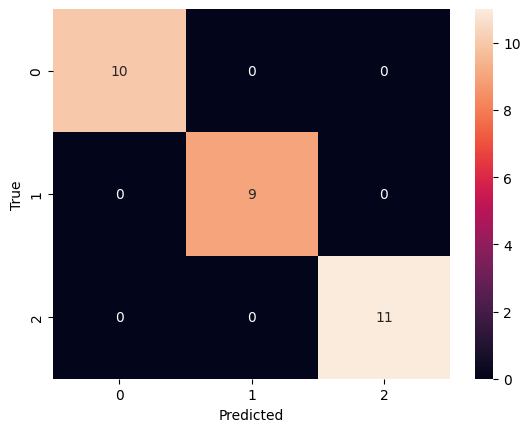

In [ ]:
# we can do this using train split test
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

# calling the model
model=KNeighborsClassifier(n_neighbors=5)

# fit the model on
model.fit(X_train,y_train)

#predict the species
y_pred=model.predict(X_test)

# evaluate the model
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.metrics import accuracy_score

confusionMatrix=confusion_matrix(y_test,y_pred)
classificationReport=classification_report(y_test,y_pred)
accuracy=accuracy_score(y_test,y_pred)
print('The accuracy of the model is:',accuracy)
print('The confusion matrix is:',confusionMatrix)
print('The classification report is:',classificationReport)
print(classification_report(y_test,y_pred))

# plot the confusion matrix
sns.heatmap(confusionMatrix,annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Regression using KNN
## Regression problem on tips dataset


In [ ]:
# load the dataset
tips=sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [ ]:
# Encoding the data
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

for col in tips.columns:
    if tips[col].dtype=='object' or tips[col].dtype=='category':
        tips[col]=le.fit_transform(tips[col])
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,0,0,2,0,2
1,10.34,1.66,1,0,2,0,3
2,21.01,3.50,1,0,2,0,3
3,23.68,3.31,1,0,2,0,2
4,24.59,3.61,0,0,2,0,4


In [ ]:
# split the data
x=tips.drop('tip',axis=1)
y=tips['tip']

In [ ]:
# train test split and run the model
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
# call the model
model=KNeighborsRegressor(n_neighbors=5)

# fit the model
model.fit(x_train,y_train)

# predict the model
y_pred=model.predict(x_test)

# evaluate the model
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
RMSE=np.sqrt(mse)
print('The mean squared error is:',mse)
print('The r2 score is:',r2)
print('The Root Mean Squared Error is" ',RMSE)

The mean squared error is: 0.8382265306122448
The r2 score is: 0.3294034029001649
The Root Mean Squared Error is"  0.9155471209130881


In [ ]:
# predict a specific values
model.predict([[19.82,1,0,1,1,3]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(


array([2.632])